In [1]:
# Import required libraries

import os
import gzip
import io
import csv
import urllib.request

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Create data directory

os.makedirs("../data", exist_ok=True)

# GEO processed expression matrix

url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE10nnn/GSE10072/matrix/"
    "GSE10072_series_matrix.txt.gz"
)

file_path = "../data/GSE10072_series_matrix.txt.gz"

# Download the dataset

if not os.path.exists(file_path):
    urllib.request.urlretrieve(url, file_path)
    print("Dataset downloaded successfully!")
else:
    print("Dataset already exists.")

print("File location:", file_path)

Dataset downloaded successfully!
File location: ../data/GSE10072_series_matrix.txt.gz


In [3]:
# Read the compressed GEO file

with gzip.open(file_path, "rt") as file:
    lines = file.readlines()

# Find beginning and ending of expression table

start = next(
    i for i, line in enumerate(lines)
    if line.startswith("!series_matrix_table_begin")
) + 1

end = next(
    i for i, line in enumerate(lines)
    if line.startswith("!series_matrix_table_end")
)

# Extract expression data

expression = pd.read_csv(
    io.StringIO("".join(lines[start:end])),
    sep="\t",
    index_col=0
)

# Convert values to numeric

expression = expression.apply(
    pd.to_numeric,
    errors="coerce"
)

print("Expression matrix shape:", expression.shape)

expression.head()

Expression matrix shape: (22283, 107)


,GSM254625,GSM254626,GSM254627,GSM254628,GSM254629,GSM254630,GSM254631,GSM254632,GSM254633,GSM254634,...,GSM254722,GSM254723,GSM254724,GSM254725,GSM254726,GSM254727,GSM254728,GSM254729,GSM254730,GSM254731
ID_REF,,,,,,,,,,,,,,,,,,,,,
1007_s_at,10.927084,10.416978,10.628538,10.151180,10.988512,10.778205,10.568814,10.479425,10.548843,10.465005,...,10.727493,10.740353,10.527962,10.193615,10.768815,10.467693,10.902778,10.869402,10.292285,10.407218
1053_at,6.895217,6.924856,7.550245,6.699557,6.826031,6.718372,6.739765,6.724615,7.102475,6.627922,...,6.856575,6.737879,6.959032,7.008578,6.740444,6.795750,6.838162,6.628363,6.794050,6.358410
117_at,8.110190,7.760228,7.974676,7.712676,7.775592,7.777087,7.893210,8.058398,8.005438,7.961476,...,7.741922,7.805107,8.093078,8.144760,8.159483,7.855457,8.010428,7.889019,8.163266,7.973844
121_at,9.451286,9.520943,9.807597,9.522087,9.855061,9.861055,10.126183,9.878970,10.110318,10.411478,...,10.089149,10.007059,9.832610,10.107004,9.790645,9.645239,9.871851,9.867988,9.824801,9.850144
1255_g_at,4.814477,4.718640,4.905163,4.818076,4.823958,4.848313,5.125956,5.037979,4.889936,5.177818,...,5.048391,4.758050,4.900470,4.948760,4.609322,4.759571,4.788774,4.967626,4.817474,5.128892


In [4]:
# Extract sample accessions

accession_line = next(
    line for line in lines
    if line.startswith("!Sample_geo_accession")
)

sample_ids = next(
    csv.reader([accession_line], delimiter="\t")
)[1:]


# Extract sample titles

title_line = next(
    line for line in lines
    if line.startswith("!Sample_title")
)

sample_titles = next(
    csv.reader([title_line], delimiter="\t")
)[1:]


# Create sample metadata

metadata = pd.DataFrame({
    "sample": sample_ids,
    "title": sample_titles
})

# Identify tumour and normal samples

metadata["condition"] = np.where(
    metadata["title"].str.contains(
        "tumor", case=False
    ),
    "Tumour",
    "Normal"
)

print(metadata["condition"].value_counts())

metadata.head()

condition
Tumour    58
Normal    49
Name: count, dtype: int64


,sample,title,condition
0,GSM254625,Lung Tumor_GT00006,Tumour
1,GSM254626,Normal Lung_GT00006,Normal
2,GSM254627,Lung Tumor_GT00007,Tumour
3,GSM254628,Normal Lung_GT00007,Normal
4,GSM254629,Lung Tumor_GT00022,Tumour


In [5]:
print("Original dimensions:", expression.shape)

print(
    "Missing values:",
    expression.isnull().sum().sum()
)

Original dimensions: (22283, 107)
Missing values: 0


In [6]:
expression = expression.dropna(axis=0)

print("After removing missing values:", expression.shape)

After removing missing values: (22283, 107)


In [7]:
print("Expression samples:", len(expression.columns))
print("Metadata samples:", len(metadata))

print(
    "All samples matched:",
    set(expression.columns) == set(metadata["sample"])
)

Expression samples: 107
Metadata samples: 107
All samples matched: True


In [8]:
# Calculate variance for each probe

gene_variance = expression.var(axis=1)

# Select the 100 most variable probes

top_genes = gene_variance.sort_values(
    ascending=False
).head(100).index

# Create filtered expression matrix

expression_filtered = expression.loc[top_genes]

print("Filtered expression dimensions:")
print(expression_filtered.shape)

Filtered expression dimensions:
(100, 107)


In [9]:
# Check dimensions

print("Number of genes:", expression_filtered.shape[0])
print("Number of samples:", expression_filtered.shape[1])

# Check for missing values

print(
    "Missing values:",
    expression_filtered.isnull().sum().sum()
)

# Check for duplicate probe IDs

print(
    "Duplicate probes:",
    expression_filtered.index.duplicated().sum()
)

# Display the input matrix

expression_filtered.head()

Number of genes: 100
Number of samples: 107
Missing values: 0
Duplicate probes: 0


,GSM254625,GSM254626,GSM254627,GSM254628,GSM254629,GSM254630,GSM254631,GSM254632,GSM254633,GSM254634,...,GSM254722,GSM254723,GSM254724,GSM254725,GSM254726,GSM254727,GSM254728,GSM254729,GSM254730,GSM254731
ID_REF,,,,,,,,,,,,,,,,,,,,,
214387_x_at,12.830445,14.428395,8.842684,14.328271,11.896303,12.399511,10.155214,13.516281,7.379175,14.379228,...,9.706984,9.723689,10.856586,14.396020,12.173078,14.560654,10.020937,13.084030,14.387332,14.361131
211735_x_at,13.296471,14.708283,9.149426,14.509592,11.955784,12.591648,10.458394,13.503528,7.948323,14.653662,...,9.881303,9.876201,11.005146,14.745708,12.557259,14.771546,10.367291,13.470301,14.730807,14.601888
205982_x_at,13.210341,14.616997,9.293764,14.539846,11.849301,12.181546,10.426598,13.529334,8.042807,14.689802,...,9.792826,9.756873,11.147391,14.553529,12.304804,14.698866,10.346851,13.328252,14.457708,14.512482
210081_at,8.938857,12.760510,6.236950,12.170162,6.766629,7.719831,7.101197,10.069160,6.411933,10.685377,...,10.614001,7.028996,7.265590,11.784894,8.015221,12.471875,7.125062,9.478140,12.740411,12.562700
209875_s_at,12.050575,7.824964,10.719797,6.971390,11.592584,10.102450,11.127330,12.273767,11.522607,7.659379,...,10.462056,10.898256,13.313324,6.920627,11.717558,5.901973,12.328181,12.245103,6.990674,7.080172


In [10]:
# Import the existing netZooPy implementations

from netZooPy.panda.panda import Panda
from netZooPy.lioness.lioness import Lioness

# Run aggregate network inference

panda_obj = Panda(
    expression_filtered,
    None,
    None,
    keep_expression_matrix=True,
    with_header=True,
    computing="cpu"
)

print("Aggregate network created!")

/home/tanmayee/miniconda3/envs/lioness/lib/python3.10/site-packages/netZooPy/sambar/sambar.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Loading motif data ...
  Elapsed time: 0.00 sec.
Loading expression data ...
  Elapsed time: 0.00 sec.
No PPI data given: ppi matrix will be an identity matrix of size 0
Calculating coexpression network ...
  Elapsed time: 0.00 sec.
Returning the correlation matrix of expression data in <Panda_obj>.correlation_matrix
union None              GSM254625  GSM254626  GSM254627  GSM254628  GSM254629  GSM254630  \
ID_REF                                                                          
214387_x_at  12.830445  14.428395   8.842684  14.328271  11.896303  12.399511   
211735_x_at  13.296471  14.708283   9.149426  14.509592  11.955784  12.591648   
205982_x_at  13.210341  14.616997   9.293764  14.539846  11.849301  12.181546   
210081_at     8.938857  12.760510   6.236950  12.170162   6.766629   7.719831   
209875_s_at  12.050575   7.824964  10.719797   6.971390  11.592584  10.102450   
...                ...        ...        ...        ...        ...        ...   
209160_at     7.636786

In [11]:
# Apply LIONESS to estimate sample-specific networks

lioness_obj = Lioness(
    panda_obj,
    computing="cpu",
    ncores=2,
    output="network",
    save_single=False
)

print("LIONESS analysis completed!")

Loading input data ...
  Elapsed time: 0.00 sec.
Number of total samples: 107
Number of computed samples: 107
Number of parallel cores: 2


/home/tanmayee/miniconda3/envs/lioness/lib/python3.10/site-packages/netZooPy/sambar/sambar.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/tanmayee/miniconda3/envs/lioness/lib/python3.10/site-packages/netZooPy/sambar/sambar.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Running LIONESS for sample 0/107:
Computing coexpression network:
  Elapsed time: 0.00 sec.
Normalizing networks:
  Elapsed time: 0.00 sec.
Inferring LIONESS network:
  Elapsed time: 0.00 sec.
Running LIONESS for sample 2/107:
Computing coexpression network:
  Elapsed time: 0.00 sec.
Normalizing networks:
  Elapsed time: 0.00 sec.
Inferring LIONESS network:
  Elapsed time: 0.00 sec.
Running LIONESS for sample 4/107:
Computing coexpression network:
  Elapsed time: 0.00 sec.
Normalizing networks:
  Elapsed time: 0.00 sec.
Inferring LIONESS network:
  Elapsed time: 0.00 sec.
Running LIONESS for sample 6/107:
Computing coexpression network:
  Elapsed time: 0.00 sec.
Normalizing networks:
  Elapsed time: 0.00 sec.
Inferring LIONESS network:
  Elapsed time: 0.00 sec.
Running LIONESS for sample 8/107:
Computing coexpression network:
  Elapsed time: 0.00 sec.
Normalizing networks:
  Elapsed time: 0.00 sec.
Inferring LIONESS network:
  Elapsed time: 0.00 sec.
Running LIONESS for sample 10/107:


In [12]:
# Extract LIONESS results

lioness_results = (
    lioness_obj.export_lioness_results.copy()
)

# Display dimensions

print("LIONESS result dimensions:")
print(lioness_results.shape)

# Display first few rows

lioness_results.head()

LIONESS result dimensions:
(10000, 109)


,gene1,gene2,GSM254625,GSM254626,GSM254627,GSM254628,GSM254629,GSM254630,GSM254631,GSM254632,...,GSM254722,GSM254723,GSM254724,GSM254725,GSM254726,GSM254727,GSM254728,GSM254729,GSM254730,GSM254731
0,201291_s_at,201291_s_at,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,201292_at,201291_s_at,0.948048,0.955295,1.080162,0.910757,0.985159,0.965726,0.960102,0.964097,...,0.995832,0.973719,1.086828,0.942171,0.949315,0.84407,0.933005,0.966304,0.997383,0.99743
2,201884_at,201291_s_at,-0.092476,0.927638,2.220813,0.750336,-0.664423,0.881602,-0.501436,-0.322527,...,-0.217189,0.448243,1.300806,0.847816,-0.367947,1.247991,0.827158,0.548348,0.993918,0.853733
3,201909_at,201291_s_at,0.245566,-0.766473,-0.39663,-0.754043,1.079735,0.436243,0.534528,0.403896,...,0.681312,-0.655466,-0.442597,-0.812816,-0.093059,-1.183556,-0.937927,0.257366,-0.850128,-0.807939
4,202310_s_at,201291_s_at,0.535157,0.929626,-0.36388,0.97046,0.844632,0.856764,0.739654,0.491865,...,0.286857,-0.789105,-0.838199,-0.160758,0.21795,0.107393,0.836889,0.724359,1.064549,0.975577


In [13]:
os.makedirs("../results", exist_ok=True)

lioness_results.to_csv(
    "../results/LIONESS_all_samples.csv"
)

print("LIONESS results saved successfully!")

LIONESS results saved successfully!


In [18]:
# Exclude gene identifier columns

numeric_results = lioness_results.drop(
    columns=["gene1", "gene2"]
)

# Convert sample columns to numeric

numeric_results = numeric_results.apply(
    pd.to_numeric,
    errors="coerce"
)

print("Numerical matrix shape:", numeric_results.shape)

display(numeric_results.head())

Numerical matrix shape: (10000, 107)


,GSM254625,GSM254626,GSM254627,GSM254628,GSM254629,GSM254630,GSM254631,GSM254632,GSM254633,GSM254634,...,GSM254722,GSM254723,GSM254724,GSM254725,GSM254726,GSM254727,GSM254728,GSM254729,GSM254730,GSM254731
0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,0.948048,0.955295,1.080162,0.910757,0.985159,0.965726,0.960102,0.964097,0.993419,0.988759,...,0.995832,0.973719,1.086828,0.942171,0.949315,0.844070,0.933005,0.966304,0.997383,0.997430
2,-0.092476,0.927638,2.220813,0.750336,-0.664423,0.881602,-0.501436,-0.322527,0.222914,0.860878,...,-0.217189,0.448243,1.300806,0.847816,-0.367947,1.247991,0.827158,0.548348,0.993918,0.853733
3,0.245566,-0.766473,-0.396630,-0.754043,1.079735,0.436243,0.534528,0.403896,0.660779,-0.506232,...,0.681312,-0.655466,-0.442597,-0.812816,-0.093059,-1.183556,-0.937927,0.257366,-0.850128,-0.807939
4,0.535157,0.929626,-0.363880,0.970460,0.844632,0.856764,0.739654,0.491865,1.037890,0.632919,...,0.286857,-0.789105,-0.838199,-0.160758,0.217950,0.107393,0.836889,0.724359,1.064549,0.975577


In [19]:
# Convert to NumPy array

edge_values = numeric_results.to_numpy(dtype=float)

# Calculate absolute edge weights

absolute_values = np.abs(edge_values.flatten())

# Remove invalid values

absolute_values = absolute_values[
    np.isfinite(absolute_values)
]

print("Total edge weights:", len(absolute_values))

Total edge weights: 1070000
Computing coexpression network:
  Elapsed time: 0.00 sec.
Normalizing networks:
  Elapsed time: 0.00 sec.
Inferring LIONESS network:
  Elapsed time: 0.00 sec.
Running LIONESS for sample 86/107:
Computing coexpression network:
  Elapsed time: 0.00 sec.
Normalizing networks:
  Elapsed time: 0.00 sec.
Inferring LIONESS network:
  Elapsed time: 0.00 sec.
Running LIONESS for sample 88/107:
Computing coexpression network:
  Elapsed time: 0.00 sec.
Normalizing networks:
  Elapsed time: 0.00 sec.
Inferring LIONESS network:
  Elapsed time: 0.00 sec.
Running LIONESS for sample 90/107:
Computing coexpression network:
  Elapsed time: 0.00 sec.
Normalizing networks:
  Elapsed time: 0.00 sec.
Inferring LIONESS network:
  Elapsed time: 0.00 sec.
Running LIONESS for sample 92/107:
Computing coexpression network:
  Elapsed time: 0.00 sec.
Normalizing networks:
  Elapsed time: 0.00 sec.
Inferring LIONESS network:
  Elapsed time: 0.00 sec.
Running LIONESS for sample 94/107:
Co

In [20]:
percentiles = [90, 95, 99]

threshold_results = []

for percentile in percentiles:

    threshold = np.percentile(
        absolute_values,
        percentile
    )

    retained_edges = np.sum(
        absolute_values >= threshold
    )

    total_edges = len(absolute_values)

    network_density = retained_edges / total_edges

    threshold_results.append({
        "Percentile": percentile,
        "Threshold": threshold,
        "Retained_edges": retained_edges,
        "Network_density": network_density
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Percentile,Threshold,Retained_edges,Network_density
0,90,1.282711,107000,0.10
1,95,1.647842,53500,0.05
2,99,2.736220,10700,0.01


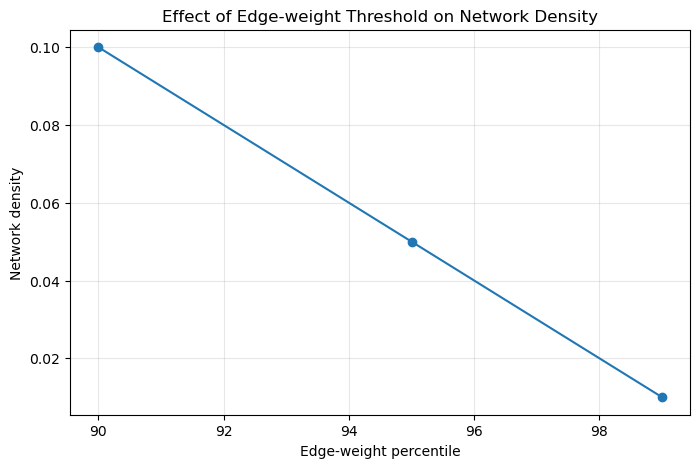

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["Percentile"],
    threshold_df["Network_density"],
    marker="o"
)

plt.xlabel("Edge-weight percentile")
plt.ylabel("Network density")

plt.title("Effect of Edge-weight Threshold on Network Density")

plt.grid(alpha=0.3)

plt.savefig(
    "../results/threshold_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
# Count self-edges

self_edges = (
    lioness_results["gene1"] ==
    lioness_results["gene2"]
).sum()

print("Number of self-edges:", self_edges)

Number of self-edges: 100


In [24]:
# Remove self-edges

filtered_results = lioness_results[
    lioness_results["gene1"] !=
    lioness_results["gene2"]
].copy()

# Extract sample-specific numerical weights

sample_weights = filtered_results.drop(
    columns=["gene1", "gene2"]
).apply(pd.to_numeric, errors="coerce")

print("Filtered network shape:", sample_weights.shape)

Filtered network shape: (9900, 107)


In [25]:
# Flatten all sample-specific edge weights

all_weights = np.abs(
    sample_weights.to_numpy(dtype=float).flatten()
)

all_weights = all_weights[np.isfinite(all_weights)]

# Calculate thresholds

thresholds = {
    p: np.percentile(all_weights, p)
    for p in [90, 95, 99]
}

print("Thresholds:", thresholds)

Thresholds: {90: np.float64(1.2873347572307687), 95: np.float64(1.6532923361955805), 99: np.float64(2.743886143126087)}


In [26]:
# Calculate network density separately for every sample

density_data = []

for percentile, threshold in thresholds.items():

    for sample in sample_weights.columns:

        values = np.abs(
            sample_weights[sample].to_numpy(dtype=float)
        )

        density = np.mean(values >= threshold)

        density_data.append({
            "Sample": sample,
            "Percentile": percentile,
            "Density": density
        })

sample_density = pd.DataFrame(density_data)

display(sample_density.head(10))

,Sample,Percentile,Density
0,GSM254625,90,0.067071
1,GSM254626,90,0.072121
2,GSM254627,90,0.220202
3,GSM254628,90,0.090303
4,GSM254629,90,0.177172
5,GSM254630,90,0.047273
6,GSM254631,90,0.065253
7,GSM254632,90,0.028283
8,GSM254633,90,0.178384
9,GSM254634,90,0.005859


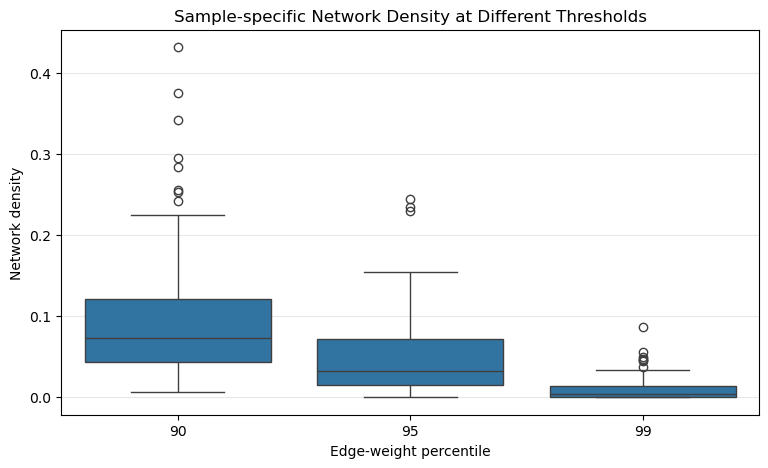

In [27]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=sample_density,
    x="Percentile",
    y="Density"
)

plt.title("Sample-specific Network Density at Different Thresholds")

plt.xlabel("Edge-weight percentile")
plt.ylabel("Network density")

plt.grid(axis="y", alpha=0.3)

plt.savefig(
    "../results/sample_specific_density.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
# Save sample-specific density results

sample_density.to_csv(
    "../results/sample_specific_density.csv",
    index=False
)

# Save threshold values

threshold_df.to_csv(
    "../results/threshold_analysis.csv",
    index=False
)

print("Step 14 results saved successfully!")

Step 14 results saved successfully!


In [29]:
# Check sample metadata

print("Metadata shape:", metadata.shape)

print("\nSample groups:")
print(metadata["condition"].value_counts())

print("\nFirst five samples:")
display(metadata.head())

Metadata shape: (107, 3)

Sample groups:
condition
Tumour    58
Normal    49
Name: count, dtype: int64

First five samples:


,sample,title,condition
0,GSM254625,Lung Tumor_GT00006,Tumour
1,GSM254626,Normal Lung_GT00006,Normal
2,GSM254627,Lung Tumor_GT00007,Tumour
3,GSM254628,Normal Lung_GT00007,Normal
4,GSM254629,Lung Tumor_GT00022,Tumour


In [30]:
# Check whether all network samples have metadata

network_samples = sample_weights.columns.tolist()

metadata_indexed = metadata.set_index("sample")

print(
    "All network samples present in metadata:",
    set(network_samples).issubset(metadata_indexed.index)
)

# Arrange metadata in the same order as network samples

metadata_indexed = metadata_indexed.loc[network_samples]

conditions = metadata_indexed["condition"]

print("\nMatched sample groups:")
print(conditions.value_counts())

All network samples present in metadata: True

Matched sample groups:
condition
Tumour    58
Normal    49
Name: count, dtype: int64


In [31]:
# Calculate Spearman correlation between sample networks

network_similarity = sample_weights.corr(
    method="spearman"
)

print("Network similarity matrix shape:")
print(network_similarity.shape)

display(network_similarity.iloc[:5, :5])

Network similarity matrix shape:
(107, 107)


,GSM254625,GSM254626,GSM254627,GSM254628,GSM254629
GSM254625,1.000000,0.440781,0.284491,0.420299,0.151469
GSM254626,0.440781,1.000000,0.254561,0.727789,0.276005
GSM254627,0.284491,0.254561,1.000000,0.380826,0.142493
GSM254628,0.420299,0.727789,0.380826,1.000000,0.278085
GSM254629,0.151469,0.276005,0.142493,0.278085,1.000000


In [32]:
# Convert similarity matrix to NumPy array

similarity_array = network_similarity.to_numpy()

labels = conditions.to_numpy()

# Create upper triangular mask
# This avoids duplicate sample pairs and self-comparisons

upper_mask = np.triu(
    np.ones(similarity_array.shape, dtype=bool),
    k=1
)

# Identify tumour-tumour pairs

tumour_mask = (
    (labels[:, None] == "Tumour") &
    (labels[None, :] == "Tumour")
)

# Identify normal-normal pairs

normal_mask = (
    (labels[:, None] == "Normal") &
    (labels[None, :] == "Normal")
)

# Identify tumour-normal pairs

between_mask = (
    labels[:, None] != labels[None, :]
)

# Calculate average similarities

tumour_values = similarity_array[
    upper_mask & tumour_mask
]

normal_values = similarity_array[
    upper_mask & normal_mask
]

between_values = similarity_array[
    upper_mask & between_mask
]

# Remove any invalid values

tumour_values = tumour_values[np.isfinite(tumour_values)]
normal_values = normal_values[np.isfinite(normal_values)]
between_values = between_values[np.isfinite(between_values)]

# Calculate means

tumour_similarity = tumour_values.mean()
normal_similarity = normal_values.mean()
between_similarity = between_values.mean()

print("Tumour-Tumour similarity:", tumour_similarity)
print("Normal-Normal similarity:", normal_similarity)
print("Tumour-Normal similarity:", between_similarity)

Tumour-Tumour similarity: 0.30724431762334564
Normal-Normal similarity: 0.5611336080050225
Tumour-Normal similarity: 0.40537092436578187


In [33]:
# Summarize network similarity

comparison_df = pd.DataFrame({
    "Comparison": [
        "Tumour-Tumour",
        "Normal-Normal",
        "Tumour-Normal"
    ],
    "Mean_Spearman_Correlation": [
        tumour_similarity,
        normal_similarity,
        between_similarity
    ],
    "Number_of_Pairs": [
        len(tumour_values),
        len(normal_values),
        len(between_values)
    ]
})

display(comparison_df)

comparison_df.to_csv(
    "../results/network_group_comparison.csv",
    index=False
)

,Comparison,Mean_Spearman_Correlation,Number_of_Pairs
0,Tumour-Tumour,0.307244,1653
1,Normal-Normal,0.561134,1176
2,Tumour-Normal,0.405371,2842


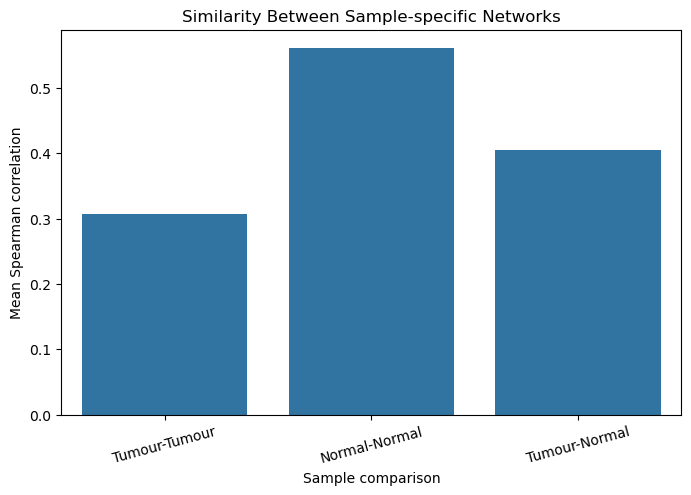

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison_df,
    x="Comparison",
    y="Mean_Spearman_Correlation"
)

plt.title("Similarity Between Sample-specific Networks")

plt.xlabel("Sample comparison")
plt.ylabel("Mean Spearman correlation")

plt.xticks(rotation=15)

plt.savefig(
    "../results/network_group_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

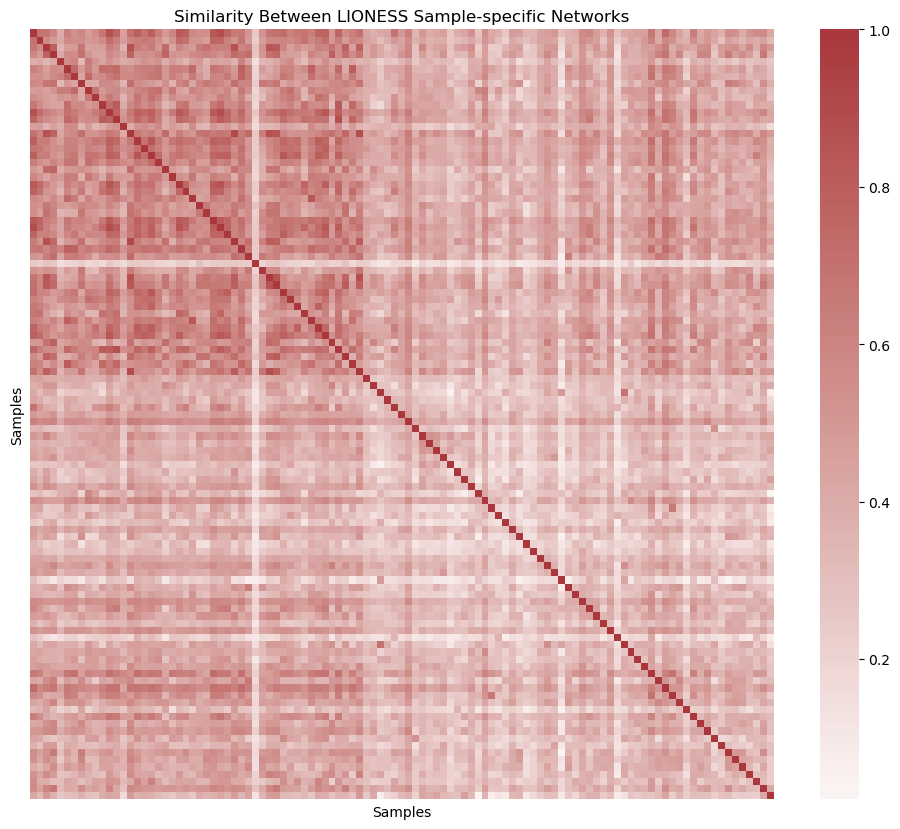

In [35]:
# Order samples by biological condition

ordered_samples = metadata_indexed.sort_values(
    "condition"
).index

ordered_similarity = network_similarity.loc[
    ordered_samples,
    ordered_samples
]

plt.figure(figsize=(12, 10))

sns.heatmap(
    ordered_similarity,
    cmap="vlag",
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title(
    "Similarity Between LIONESS Sample-specific Networks"
)

plt.xlabel("Samples")
plt.ylabel("Samples")

plt.savefig(
    "../results/network_similarity_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
# Save network similarity matrix

network_similarity.to_csv(
    "../results/network_similarity.csv"
)

# Save group comparison

comparison_df.to_csv(
    "../results/network_group_comparison.csv",
    index=False
)

# Save metadata

metadata.to_csv(
    "../results/sample_metadata.csv",
    index=False
)

print("Step 15 completed and all results saved!")

Step 15 completed and all results saved!


In [1]:
import os

print("Current notebook directory:")
print(os.getcwd())

print("\nResults directory:")
print(os.path.abspath("../results"))

print("\nDoes results directory exist?")
print(os.path.exists("../results"))

Current notebook directory:
/home/tanmayee/SBNM_LIONESS_Project/notebooks

Results directory:
/home/tanmayee/SBNM_LIONESS_Project/results

Does results directory exist?
True


In [3]:
%whos

Variable   Type      Data/Info
------------------------------
os         module    <module 'os' from '/home/<...>ss/lib/python3.10/os.py'>


In [1]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nAbsolute results path:")
print(os.path.abspath("../results"))

print("\nDoes results folder exist?")
print(os.path.exists("../results"))

print("\nContents of results folder:")
print(os.listdir("../results"))

Current working directory:
/home/tanmayee/SBNM_LIONESS_Project/notebooks

Absolute results path:
/home/tanmayee/SBNM_LIONESS_Project/results

Does results folder exist?
True

Contents of results folder:
[]


In [2]:
print("LIONESS results shape:", lioness_results.shape)
print("Sample weights shape:", sample_weights.shape)
print("Sample density shape:", sample_density.shape)
print("Threshold summary shape:", threshold_df.shape)
print("Metadata shape:", metadata.shape)
print("Network comparison shape:", comparison_df.shape)
print("Similarity matrix shape:", network_similarity.shape)

NameError: name 'lioness_results' is not defined

In [ ]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

# Load saved LIONESS output
lioness_results = pd.read_csv(
    "../results/LIONESS_all_samples.csv",
    index_col=0
)

print("LIONESS shape:", lioness_results.shape)